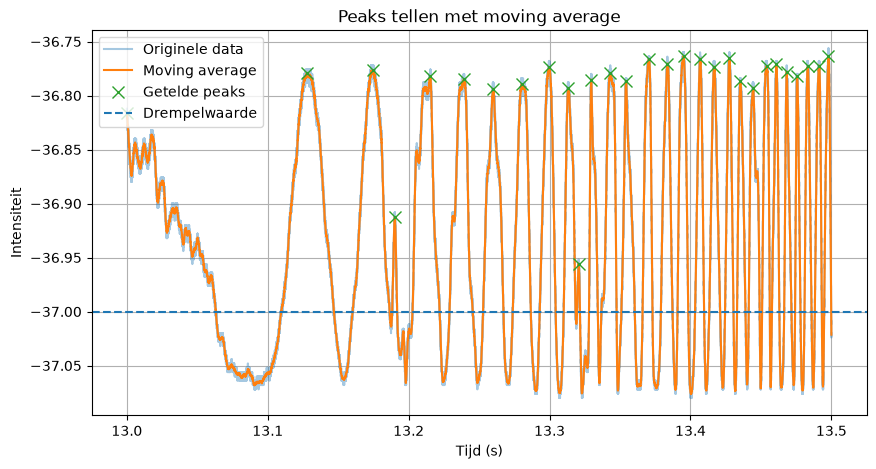

29 peaks
250001


In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

data = np.loadtxt("tes metingen vrijdag/40 graden veel meetpunten3.csv", delimiter=",",usecols=(0, 1), skiprows=3)

t = data[:, 0]
i = data[:, 1]

BEGIN = 13
EIND = 13.5
DREMPEL = -37
SIGMA = 12

masker = (t >= BEGIN) & (t <= EIND)
t = t[masker]
i = i[masker]

i_gemiddeld = gaussian_filter1d(i, sigma=SIGMA)

# Peaks tellen: één top per stuk signaal boven de drempel
peaks = []          # <- begint leeg, alleen hier gevuld
in_piek = False
start = 0

for j in range(len(i_gemiddeld)):
    if i_gemiddeld[j] > DREMPEL and not in_piek:
        in_piek = True
        start = j
    elif i_gemiddeld[j] < DREMPEL and in_piek:
        in_piek = False
        peaks.append(start + np.argmax(i_gemiddeld[start:j]))

if in_piek:
    peaks.append(start + np.argmax(i_gemiddeld[start:]))

aantal = len(peaks)

# Grafiek
plt.figure(figsize=(10, 5))
plt.plot(t, i, alpha=0.4, label="Originele data")
plt.plot(t, i_gemiddeld, label="Moving average")
plt.plot(t[peaks], i_gemiddeld[peaks], "x", markersize=8, label="Getelde peaks")
plt.axhline(DREMPEL, linestyle="--", label="Drempelwaarde")
plt.xlabel("Tijd (s)")
plt.ylabel("Intensiteit")
plt.title("Peaks tellen met moving average")
plt.grid()
plt.legend()
plt.show()

print(f"{aantal} peaks")
print(len(i_gemiddeld))


In [111]:
import numpy as np
import matplotlib.pyplot as plt

data = data

print(data)
print(data.shape)

[[ -5.505996 -37.036   ]
 [ -5.505994 -37.032   ]
 [ -5.505992 -37.032   ]
 ...
 [ 14.623244 -37.084   ]
 [ 14.623246 -37.084   ]
 [ 14.623248 -37.08    ]]
(10064623, 2)


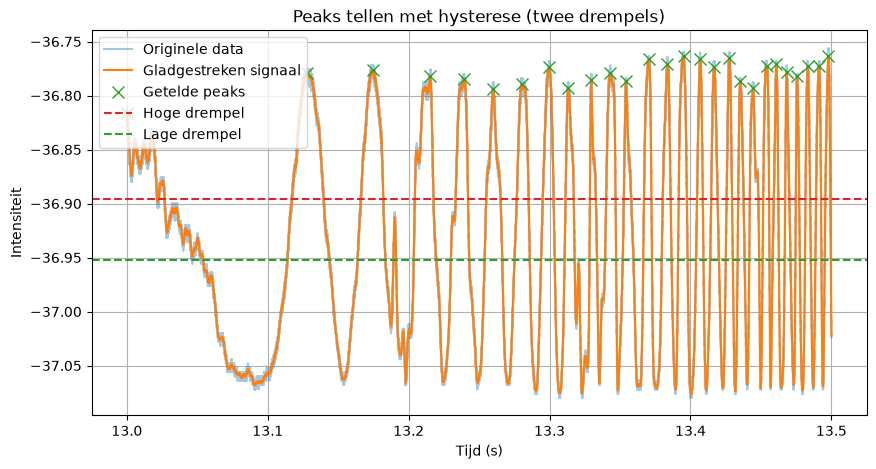

27 peaks (hysterese)
27 peaks (controle met find_peaks)
ruis (std) = 0.0000
hoge drempel = -36.8959, lage drempel = -36.9526, band = 0.0567
aantal samples: 250001


In [29]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

# ---------------- Instellingen ----------------
BESTAND = "tes metingen vrijdag/40 graden veel meetpunten3.csv"
BEGIN = 13
EIND = 13.5
SIGMA = 12

# Drempels: zet op None voor automatisch (uit het signaal zelf),
# of vul zelf waarden in, bijv. DREMPEL_HOOG = -36.9 en DREMPEL_LAAG = -37.5
DREMPEL_HOOG = None
DREMPEL_LAAG = None
BAND_FACTOR = 3      # halve band is minstens zoveel keer de ruis (std)
BAND_FRACTIE = 0.10  # ... en minstens zo'n fractie van de piek-dal hoogte
# -----------------------------------------------

data = np.loadtxt(BESTAND, delimiter=",", usecols=(0, 1), skiprows=3)
t = data[:, 0]
i = data[:, 1]

masker = (t >= BEGIN) & (t <= EIND)
t = t[masker]
i = i[masker]

i_gemiddeld = gaussian_filter1d(i, sigma=SIGMA)

# Ruis schatten uit sample-tot-sample verschillen (robuust, niet afhankelijk van SIGMA)
verschil = np.diff(i)
ruis = 1.4826 * np.median(np.abs(verschil - np.median(verschil))) / np.sqrt(2)

# Drempels bepalen
top, dal = np.percentile(i_gemiddeld, [95, 5])
midden = (top + dal) / 2
halve_band = max(BAND_FACTOR * ruis, BAND_FRACTIE * (top - dal))

hoog = DREMPEL_HOOG if DREMPEL_HOOG is not None else midden + halve_band
laag = DREMPEL_LAAG if DREMPEL_LAAG is not None else midden - halve_band

if hoog <= laag:
    raise ValueError("DREMPEL_HOOG moet groter zijn dan DREMPEL_LAAG")

# Peaks tellen met hysterese:
# een peak begint pas als het signaal boven 'hoog' komt en eindigt pas
# als het onder 'laag' zakt. Ruis binnen de band doet niets.
peaks = []
in_piek = False
start = 0

for j in range(len(i_gemiddeld)):
    if i_gemiddeld[j] > hoog and not in_piek:
        in_piek = True
        start = j
    elif i_gemiddeld[j] < laag and in_piek:
        in_piek = False
        peaks.append(start + np.argmax(i_gemiddeld[start:j]))

if in_piek:
    peaks.append(start + np.argmax(i_gemiddeld[start:]))

peaks = np.array(peaks, dtype=int)
aantal = len(peaks)

# Controle: onafhankelijke telling met find_peaks (prominence = bandbreedte)
controle, _ = find_peaks(i_gemiddeld, prominence=hoog - laag)

# Grafiek
plt.figure(figsize=(10, 5))
plt.plot(t, i, alpha=0.4, label="Originele data")
plt.plot(t, i_gemiddeld, label="Gladgestreken signaal")
plt.plot(t[peaks], i_gemiddeld[peaks], "x", markersize=8, label="Getelde peaks")
plt.axhline(hoog, linestyle="--", color="tab:red", label="Hoge drempel")
plt.axhline(laag, linestyle="--", color="tab:green", label="Lage drempel")
plt.xlabel("Tijd (s)")
plt.ylabel("Intensiteit")
plt.title("Peaks tellen met hysterese (twee drempels)")
plt.grid()
plt.legend()
plt.show()

print(f"{aantal} peaks (hysterese)")
print(f"{len(controle)} peaks (controle met find_peaks)")
print(f"ruis (std) = {ruis:.4f}")
print(f"hoge drempel = {hoog:.4f}, lage drempel = {laag:.4f}, band = {hoog - laag:.4f}")
print(f"aantal samples: {len(i_gemiddeld)}")